In [2]:
import sys
sys.path.insert(0, '..')
from wakai.catalog import *

In [59]:
df_orig = get_nexsci_data(clobber=False) #set to True when updating
df_orig.tail()

Column definitions:  https://exoplanetarchive.ipac.caltech.edu/docs/API_PS_columns.html


UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]
UnitTypeError("MaskedQuantity instances require normal units, not <class 'astropy.units.function.logarithmic.DexUnit'> instances.") [astropy.table.table]


Saved:  ../data/nexsci_ps.csv


,pl_name,pl_letter,hostname,hd_name,hip_name,tic_id,gaia_id,default_flag,pl_refname,sy_refname,...,sy_jmagstr,sy_hmag,sy_hmagerr1,sy_hmagerr2,sy_hmagstr,sy_kmag,sy_kmagerr1,sy_kmagerr2,sky_coord.ra,sky_coord.dec
32865,TOI-237 b,b,TOI-237,,,TIC 305048087,Gaia DR2 2329387852426700800,0,<a refstr=EXOFOP_TESS_TOI href=https://exofop....,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,...,11.740&plusmn;0.021,11.190,0.022,-0.022,11.190&plusmn;0.022,10.896,0.025,-0.025,353.243538,-29.416487
32866,HD 1397 b,b,HD 1397,HD 1397,HIP 1419,TIC 394137592,Gaia DR2 4707634458245031552,0,<a refstr=EXOFOP_TESS_TOI href=https://exofop....,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,...,6.442&plusmn;0.020,6.090,0.049,-0.049,6.090&plusmn;0.049,5.988,0.018,-0.018,4.447163,-66.358929
32867,OGLE2-TR-L9 b,b,OGLE2-TR-L9,,,TIC 466840711,Gaia DR2 5337273743301313536,1,<a refstr=SNELLEN_ET_AL__2009 href=https://ui....,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,...,13.508&plusmn;0.032,13.246,0.035,-0.035,13.246&plusmn;0.035,13.117,0.037,-0.037,166.979879,-61.146250
32868,CoRoT-12 b,b,CoRoT-12,,,TIC 280210963,Gaia DR2 3107255598526406912,0,<a refstr=BONOMO_ET_AL__2017 href=https://ui.a...,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,...,14.024&plusmn;0.032,13.630,0.031,-0.031,13.630&plusmn;0.031,13.557,0.042,-0.042,100.765687,-1.296444
32869,CoRoT-20 b,b,CoRoT-20,,,TIC 234825296,Gaia DR2 3120122805143587328,0,<a refstr=BONOMO_ET_AL__2017 href=https://ui.a...,<a refstr=STASSUN_ET_AL__2019 href=https://ui....,...,12.991&plusmn;0.026,12.652,0.027,-0.027,12.652&plusmn;0.027,12.513,0.029,-0.029,97.720425,0.226893


In [60]:
df = df_orig[df_orig['default_flag']==1]
df.shape

(4307, 356)

In [61]:
nsys = df['hostname'].value_counts()
nsys

hostname
KOI-351        8
TRAPPIST-1     7
Kepler-80      6
TOI-178        6
HD 110067      6
              ..
Kepler-1465    1
Kepler-774     1
Kepler-892     1
Kepler-1792    1
Kepler-1274    1
Name: count, Length: 3259, dtype: int64

In [62]:
host_multis = list(nsys[nsys>1].index)
print(len(host_multis))

683


In [8]:
df_young = df[df.st_age<1]
df_young.shape

(124, 356)

In [9]:
young_multis = df_young[df_young.hostname.isin(host_multis)]
len(young_multis.hostname.unique())

21

Text(0.5, 0, 'Orbital period (days)')

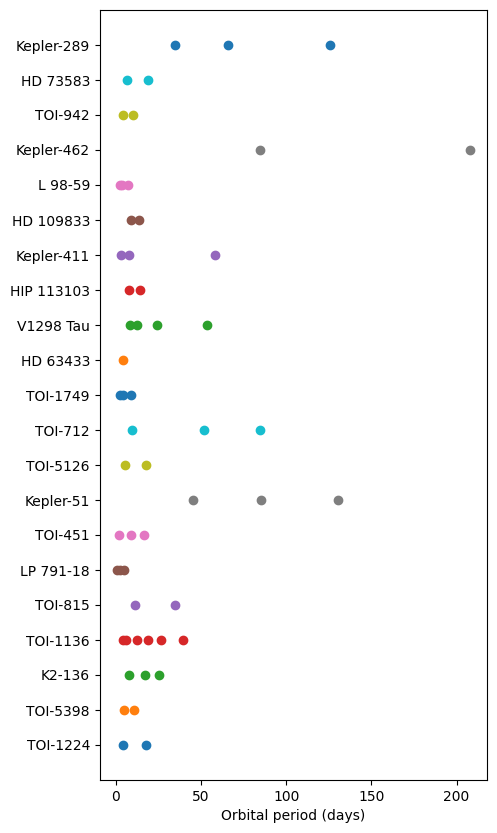

In [10]:
import matplotlib.pyplot as pl

fig, ax = pl.subplots(figsize=(5,10))
names = []
for i,name in enumerate(young_multis.hostname.unique()):
    #print(hostname)
    d = young_multis[young_multis.hostname==name]
    for j,row in d.iterrows():
        ax.plot(row.pl_orbper, i, 'o', c=f'C{i}')
    names.append(name)
ax.set_yticks(range(len(names)), names);
ax.set_xlabel("Orbital period (days)")

## ages

In [63]:
import pandas as pd

distance = 500

fp = "../data/young_validated_planets_TOIs.xlsx"
hosts = pd.read_excel(fp, sheet_name='hosts', skiprows=[1]).dropna(subset=['Host'])
hosts = hosts[hosts.distance<distance]
planets = pd.read_excel(fp, sheet_name='planets', skiprows=[1]).dropna(subset=['Host'])

In [64]:
hostnames = hosts.Host.apply(lambda x: x.lower().replace(' ', ''))
hostnames

0            k2-33
2         toi-1227
3         hip67522
5            aumic
6         v1298tau
8         hd109833
9         koi-7368
10       koi-7913a
11         toi-837
13    kepler-1627a
14          dstuca
15     kepler-1643
17         toi-942
19        hip94235
21         toi-251
22      kepler-970
23     kepler-1928
26         toi-451
27        hd235088
32        toi-2076
34        toi-1807
35        hd110082
37        toi-2048
38        toi-2046
39        toi-1027
40        toi-4562
41         hd18599
43        toi-1683
44         hd63433
46         hd73583
48        hd207496
50        toi-1136
54           k2-25
56          k2-136
57        toi-1201
59           k2-95
60          k2-100
62          k2-101
63          k2-102
64          k2-103
65          k2-104
66          k2-264
67          k2-284
68          k2-233
Name: Host, dtype: object

In [65]:
hosts['Host'] = hosts.Host.apply(lambda x: x.lower().replace(' ', ''))
df['Host'] = df.hostname.apply(lambda x: x.lower().replace(' ', ''))

/tmp/ipykernel_3588272/1001689052.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Host'] = df.hostname.apply(lambda x: x.lower().replace(' ', ''))


In [80]:
hosts['Age_lower'] = hosts['Age'].apply(lambda x: str(x).split('-')[0]).values
hosts['Age_upper'] = hosts['Age'].apply(lambda x: str(x).split('-')[1]).values

In [72]:
df_young = df[df.Host.isin(hosts.Host)]
df_young.shape

(65, 357)

In [91]:
df_young.query("hostname=='K2-198'")

,pl_name,pl_letter,hostname,hd_name,hip_name,tic_id,gaia_id,default_flag,pl_refname,sy_refname,...,sy_hmag,sy_hmagerr1,sy_hmagerr2,sy_hmagstr,sy_kmag,sy_kmagerr1,sy_kmagerr2,sky_coord.ra,sky_coord.dec,Host


In [73]:
nsys = df_young.Host.value_counts()
(nsys>1).sum()

13

In [74]:
host_multis = list(nsys[nsys>1].index)
print(len(host_multis))

13


In [75]:
host_multis

['toi-1136',
 'v1298tau',
 'toi-2076',
 'k2-233',
 'toi-451',
 'k2-136',
 'hd63433',
 'aumic',
 'hip67522',
 'toi-942',
 'k2-264',
 'hd73583',
 'hd109833']

In [76]:
young_multis = df_young[df_young.Host.isin(host_multis)]
len(young_multis.hostname.unique())

13

Text(0.5, 0, 'Orbital period (days)')

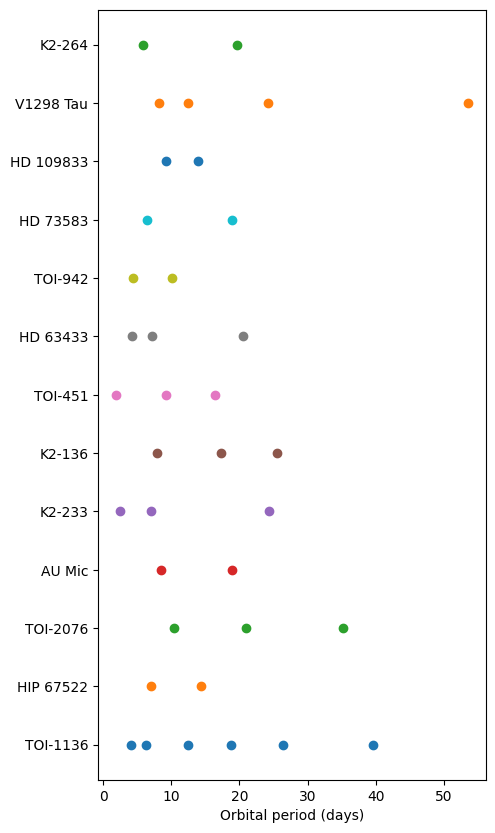

In [86]:
import matplotlib.pyplot as pl

fig, ax = pl.subplots(figsize=(5,10))
names = []
for i,name in enumerate(young_multis.hostname.unique()):
    #print(hostname)
    d = young_multis[young_multis.hostname==name]
    for j,row in d.iterrows():
        ax.plot(row.pl_orbper, i, 'o', c=f'C{i}')
    names.append(name)
ax.set_yticks(range(len(names)), names);
ax.set_xlabel("Orbital period (days)")